# 31 -- Step 8: train the minus channel, reusing the R baseline as the plus channel

Section 01d of the HTML page (Steps 1-7) now describes two parallel real-valued
RBMs, `W+`/`c+`/`d+` and `W-`/`c-`/`d-`, both fed the **same** real input `a`
(the normalized rating) -- they differ only through their own weights and
biases. This notebook does not touch the HTML; it only trains the data behind
a future Step 8.

Plan: locate the existing R (real) baseline RBM, verify it matches the plus
channel's required architecture exactly, reuse its *trained* weights as
`W+`/`c+`/`d+` (no retraining), train only the minus channel (`W-`/`c-`/`d-`)
with the same code and hyperparameters but a different seed, then save
everything Step 8 needs: a one-line hyperparameter summary and a fully
worked single-user CD-1 update.

## Part 0 -- Setup: scan notebooks/outputs, pick this notebook's number

In [1]:
from pathlib import Path
import json
import re
import time

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
notebooks_dir = root / "notebooks"
data_dir = root / "data"
out_dir = root / "outputs"
out_dir.mkdir(parents=True, exist_ok=True)

nb_paths = sorted(p for p in notebooks_dir.glob("*.ipynb") if "step8_minus_channel" not in p.stem)
num_re = re.compile(r"^(\d+)")
numbered = sorted(
    (int(m.group(1)), p) for p in nb_paths if (m := num_re.match(p.stem))
)
highest_num, highest_path = numbered[-1]
this_num = highest_num + 1
this_name = f"{this_num}_step8_minus_channel.ipynb"
print(f"highest existing notebook: {highest_num:>3d}  ({highest_path.name})")
print(f"this notebook is:          {this_num:>3d}  ({this_name})")
print(f"data dir:   {data_dir}")
print(f"outputs dir: {out_dir}")

highest existing notebook:  30  (30_hyperbolic_weights.ipynb)
this notebook is:           31  (31_step8_minus_channel.ipynb)
data dir:   /Users/yixuan/Boltzmann Machine in Movie Lens/rbm-recsys/data
outputs dir: /Users/yixuan/Boltzmann Machine in Movie Lens/rbm-recsys/outputs


## Part 1 -- Find and verify the existing R baseline RBM

Required to match: 128 hidden units, sigmoid units, trained on the normalized
rating `a`, on the 1000x1000 chronological train split. If it doesn't match,
stop and report the mismatch instead of silently retraining.

In [2]:
train_path = data_dir / "train_hyperbolic.csv"
test_path = data_dir / "test_hyperbolic.csv"
w_real_path = data_dir / "W_real.npy"
hbias_real_path = data_dir / "hbias_real.npy"
vbias_real_path = data_dir / "vbias_real.npy"
for p in (train_path, test_path, w_real_path, hbias_real_path, vbias_real_path):
    assert p.exists(), f"Missing {p}"

train_hyp = pd.read_csv(train_path)
test_hyp = pd.read_csv(test_path)
print(f"train rows: {len(train_hyp):,}  test rows: {len(test_hyp):,}")

# Cross-check against the HTML page's section 03 "Chronological Train / Test Split" numbers
# (492,055 train / 123,474 test) -- confirms this IS the 1000x1000 chronological split.
assert len(train_hyp) == 492055 and len(test_hyp) == 123474, \
    f"Row counts don't match the page's section 03 split: got {len(train_hyp)}/{len(test_hyp)}"
print("Row counts match section 03's chronological split (492,055 / 123,474). OK.")

W_real = np.load(w_real_path)
hbias_real = np.load(hbias_real_path)
vbias_real = np.load(vbias_real_path)
print(f"W_real shape:      {W_real.shape}")
print(f"hbias_real shape:  {hbias_real.shape}")
print(f"vbias_real shape:  {vbias_real.shape}")

# Inspect notebook 26's source directly -- the notebook that actually produced these
# three .npy files -- rather than assuming its architecture.
reused_path = notebooks_dir / "26_drbm_energy_cd1_training.ipynb"
assert reused_path.exists(), f"Missing {reused_path}"
reused_src = "\n".join(
    "".join(c.get("source", [])) if isinstance(c.get("source"), list) else c.get("source", "")
    for c in json.loads(reused_path.read_text()).get("cells", [])
)

def read_hparam(name, cast):
    m = re.search(rf"^{name}\s*=\s*([0-9.eE+-]+)", reused_src, flags=re.MULTILINE)
    assert m, f"Could not find {name} in {reused_path.name}"
    return cast(m.group(1))

N_HIDDEN = read_hparam("N_HIDDEN", int)
BATCH_SIZE = read_hparam("BATCH_SIZE", int)
EPOCHS = read_hparam("EPOCHS", int)
LR = read_hparam("LR", float)
real_seed_match = re.search(r'rbm_real = RBM\(n_visible=n_movies, n_hidden=N_HIDDEN, seed=(\d+)\)', reused_src)
assert real_seed_match, "Could not find rbm_real's init seed in notebook 26"
REAL_SEED = int(real_seed_match.group(1))

checks = {
    "128 hidden units": (N_HIDDEN == 128, f"N_HIDDEN={N_HIDDEN}"),
    "sigmoid visible+hidden units": ("torch.sigmoid" in reused_src, "torch.sigmoid present in RBM class"),
    "trained on normalized rating a": ('build_matrix(train_hyp, "a")' in reused_src, 'build_matrix(train_hyp, "a") present'),
    "W_real shape is (1000, 128)": (W_real.shape == (1000, 128), f"shape={W_real.shape}"),
}
all_ok = True
for name, (ok, detail) in checks.items():
    print(f"  [{'OK' if ok else 'MISMATCH'}] {name}: {detail}")
    all_ok = all_ok and ok

if not all_ok:
    raise RuntimeError("R baseline architecture does not match the required spec -- stopping per instructions.")

print()
print(f"R baseline MATCHES. Reusing notebook: {reused_path.name}")
print(f"Hyperparameters read from it: N_HIDDEN={N_HIDDEN}, BATCH_SIZE={BATCH_SIZE}, EPOCHS={EPOCHS}, LR={LR}")
print(f"R baseline (plus-channel) init seed: {REAL_SEED}")

train rows: 492,055  test rows: 123,474
Row counts match section 03's chronological split (492,055 / 123,474). OK.
W_real shape:      (1000, 128)
hbias_real shape:  (128,)
vbias_real shape:  (1000,)
  [OK] 128 hidden units: N_HIDDEN=128
  [OK] sigmoid visible+hidden units: torch.sigmoid present in RBM class
  [OK] trained on normalized rating a: build_matrix(train_hyp, "a") present
  [OK] W_real shape is (1000, 128): shape=(1000, 128)

R baseline MATCHES. Reusing notebook: 26_drbm_energy_cd1_training.ipynb
Hyperparameters read from it: N_HIDDEN=128, BATCH_SIZE=100, EPOCHS=50, LR=0.05
R baseline (plus-channel) init seed: 44


## Part 2 -- Reuse the R baseline as the plus channel (no retraining)

`W+ = W_real`, `c+ = hbias_real` (hidden bias), `d+ = vbias_real` (visible
bias, one per movie) -- loaded as-is, not retrained.

In [3]:
W_plus = torch.tensor(W_real)
c_plus = torch.tensor(hbias_real)
d_plus = torch.tensor(vbias_real)
print(f"W+ : {tuple(W_plus.shape)}  (reused from {w_real_path.name}, untouched)")
print(f"c+ : {tuple(c_plus.shape)}  (reused from {hbias_real_path.name}, untouched)")
print(f"d+ : {tuple(d_plus.shape)}  (reused from {vbias_real_path.name}, untouched)")

W+ : (1000, 128)  (reused from W_real.npy, untouched)
c+ : (128,)  (reused from hbias_real.npy, untouched)
d+ : (1000,)  (reused from vbias_real.npy, untouched)


## Part 3 -- Train the minus channel: same code, same hyperparameters, different seed

Reuses notebook 26's exact `RBM` class and masked CD-1 training loop,
unmodified, trained on the same visible input `a`. Only the random seed
differs from the plus channel's (44), so the two channels start from
different initial weights and see batches in a different order.

In [4]:
MINUS_SEED = REAL_SEED + 1  # 45: different from the plus channel's seed (44), same code otherwise

all_users = sorted(pd.concat([train_hyp["userId"], test_hyp["userId"]]).unique())
all_movies = sorted(pd.concat([train_hyp["movieId"], test_hyp["movieId"]]).unique())
n_users, n_movies = len(all_users), len(all_movies)
user_to_row = {u: i for i, u in enumerate(all_users)}
movie_to_col = {m: j for j, m in enumerate(all_movies)}
print(f"n_users={n_users}  n_movies={n_movies}  minus-channel seed={MINUS_SEED}")

def build_matrix(df, value_col):
    mat = torch.zeros(n_users, n_movies, dtype=torch.float32)
    mask = torch.zeros(n_users, n_movies, dtype=torch.float32)
    rows = torch.tensor(df["userId"].map(user_to_row).values, dtype=torch.long)
    cols = torch.tensor(df["movieId"].map(movie_to_col).values, dtype=torch.long)
    vals = torch.tensor(df[value_col].values, dtype=torch.float32)
    mat[rows, cols] = vals
    mask[rows, cols] = 1.0
    return mat, mask

v_train, mask_train = build_matrix(train_hyp, "a")
print(f"v_train: {tuple(v_train.shape)}  observed cells={int(mask_train.sum()):,}")

n_users=1000  n_movies=1000  minus-channel seed=45
v_train: (1000, 1000)  observed cells=492,055


In [5]:
class RBM:
    """Identical to notebook 26's RBM class (same code, reused as instructed)."""
    def __init__(self, n_visible, n_hidden, seed=42, device="cpu"):
        g = torch.Generator(device=device).manual_seed(seed)
        self.n_visible = n_visible
        self.n_hidden = n_hidden
        self.device = device
        self.W = (torch.randn(n_visible, n_hidden, generator=g, device=device) * 0.01)
        self.vbias = torch.zeros(n_visible, device=device)
        self.hbias = torch.zeros(n_hidden, device=device)

    def sample_h(self, v):
        h_prob = torch.sigmoid(v @ self.W + self.hbias)
        h_sample = torch.bernoulli(h_prob)
        return h_prob, h_sample

    def sample_v(self, h):
        return torch.sigmoid(h @ self.W.t() + self.vbias)

    def reconstruct(self, v, mask=None):
        h_prob = torch.sigmoid(v @ self.W + self.hbias)
        v_prob = torch.sigmoid(h_prob @ self.W.t() + self.vbias)
        if mask is not None:
            v_prob = v_prob * mask
        return v_prob

    def cd1_step(self, v0, mask, lr):
        bs = v0.shape[0]
        h0_prob, h0_sample = self.sample_h(v0)
        v1_prob = self.sample_v(h0_sample) * mask
        h1_prob, _ = self.sample_h(v1_prob)

        pos = v0.t() @ h0_prob
        neg = v1_prob.t() @ h1_prob
        self.W += lr * (pos - neg) / bs
        self.vbias += lr * (v0 - v1_prob).sum(dim=0) / bs
        self.hbias += lr * (h0_prob - h1_prob).sum(dim=0) / bs

        n_obs = mask.sum().clamp(min=1)
        mse = (((v0 - v1_prob) ** 2) * mask).sum() / n_obs
        return mse.item()

    def train(self, v_full, mask_full, batch_size, epochs, lr, seed=42, verbose=True):
        n = v_full.shape[0]
        g = torch.Generator().manual_seed(seed)
        history = []
        for epoch in range(epochs):
            order = torch.randperm(n, generator=g)
            epoch_mse, n_batches = 0.0, 0
            for start in range(0, n, batch_size):
                idx = order[start:start + batch_size]
                mse = self.cd1_step(v_full[idx], mask_full[idx], lr)
                epoch_mse += mse
                n_batches += 1
            epoch_mse /= n_batches
            history.append(epoch_mse)
            if verbose and (epoch + 1) % 10 == 0:
                print(f"  epoch {epoch + 1:3d}/{epochs}: reconstruction MSE (masked) = {epoch_mse:.5f}")
        return history

print(f"training RBM_minus (seed={MINUS_SEED})...")
t0 = time.perf_counter()
rbm_minus = RBM(n_visible=n_movies, n_hidden=N_HIDDEN, seed=MINUS_SEED)
history_minus = rbm_minus.train(v_train, mask_train, BATCH_SIZE, EPOCHS, LR, seed=MINUS_SEED)
print(f"done in {time.perf_counter() - t0:.1f}s, final MSE={history_minus[-1]:.5f}")

W_minus = rbm_minus.W
c_minus = rbm_minus.hbias
d_minus = rbm_minus.vbias

training RBM_minus (seed=45)...
  epoch  10/50: reconstruction MSE (masked) = 0.03862


  epoch  20/50: reconstruction MSE (masked) = 0.03769


  epoch  30/50: reconstruction MSE (masked) = 0.03669
  epoch  40/50: reconstruction MSE (masked) = 0.03607


  epoch  50/50: reconstruction MSE (masked) = 0.03570
done in 0.4s, final MSE=0.03570


saved 31_W_minus.npy, 31_c_minus.npy, 31_d_minus.npy to outputs/


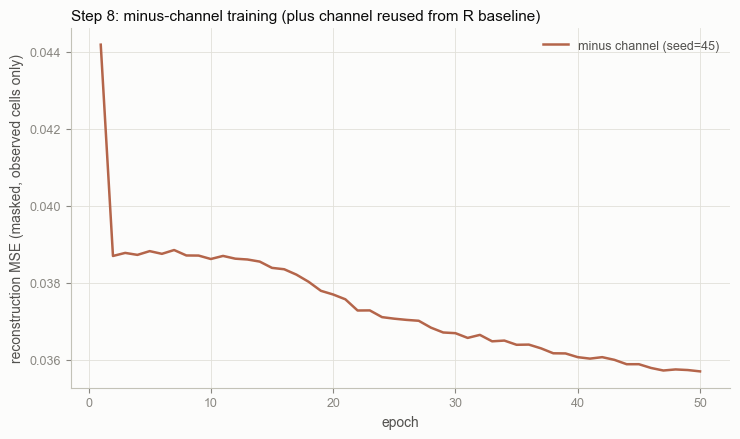

saved /Users/yixuan/Boltzmann Machine in Movie Lens/rbm-recsys/outputs/31_minus_channel_training_loss.png


In [6]:
np.save(out_dir / f"31_W_minus.npy", W_minus.numpy())
np.save(out_dir / f"31_c_minus.npy", c_minus.numpy())
np.save(out_dir / f"31_d_minus.npy", d_minus.numpy())
print("saved 31_W_minus.npy, 31_c_minus.npy, 31_d_minus.npy to outputs/")

INK_PRIMARY, INK_SECONDARY, INK_MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams["font.family"] = ["Arial", "Helvetica", "DejaVu Sans"]

fig, ax = plt.subplots(figsize=(7.5, 4.5), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.plot(range(1, EPOCHS + 1), history_minus, color="#b4654a", linewidth=1.8, label=f"minus channel (seed={MINUS_SEED})", zorder=3)
ax.set_xlabel("epoch", color=INK_SECONDARY, fontsize=10)
ax.set_ylabel("reconstruction MSE (masked, observed cells only)", color=INK_SECONDARY, fontsize=10)
ax.set_title("Step 8: minus-channel training (plus channel reused from R baseline)", color=INK_PRIMARY, fontsize=11, loc="left")
ax.legend(loc="best", frameon=False, fontsize=9, labelcolor=INK_SECONDARY)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
for s in ("left", "bottom"):
    ax.spines[s].set_color(BASELINE)
ax.tick_params(colors=INK_MUTED, labelsize=9)
ax.grid(color=GRID, linewidth=0.6, zorder=0)
plt.tight_layout()
fig_path = out_dir / "31_minus_channel_training_loss.png"
plt.savefig(fig_path, dpi=150, facecolor=SURFACE)
plt.show()
print(f"saved {fig_path}")

## Part 4a -- Hyperparameters, one line

In [7]:
hparam_line = (
    f"lr={LR}, {EPOCHS} epochs, CD-1 (1 Gibbs step), batch size={BATCH_SIZE} users, "
    f"N_HIDDEN={N_HIDDEN}, masked (test positions excluded), "
    f"plus_seed={REAL_SEED} (reused from R baseline, not retrained), minus_seed={MINUS_SEED}"
)
print(hparam_line)

lr=0.05, 50 epochs, CD-1 (1 Gibbs step), batch size=100 users, N_HIDDEN=128, masked (test positions excluded), plus_seed=44 (reused from R baseline, not retrained), minus_seed=45


## Part 4b -- Worked example: one single-user CD-1 update at (Rumble in the Bronx, h1)

Movie: Rumble in the Bronx, found by title. User: among training users who
rated it 4.0, the one with the median total rating count (ties broken by
ascending userId). Uses the plus channel's **initial** weights (recreated
from the R baseline's own seed, 44) -- not the trained weights -- since the
point is to show one hand-computable CD-1 step.

In [8]:
movies = pd.read_csv(data_dir / "movie.csv")
rumble_row = movies[movies["title"].str.contains("Rumble in the Bronx", case=False, na=False)]
assert len(rumble_row) == 1, f"Expected exactly one match, got {len(rumble_row)}"
RUMBLE_ID = int(rumble_row.iloc[0]["movieId"])
RUMBLE_TITLE = rumble_row.iloc[0]["title"]
rumble_col = movie_to_col[RUMBLE_ID]
print(f"movie: {RUMBLE_TITLE} (movieId={RUMBLE_ID}, column={rumble_col})")

rumble4 = train_hyp[(train_hyp["movieId"] == RUMBLE_ID) & (train_hyp["rating"] == 4.0)].copy()
train_counts = train_hyp.groupby("userId").size()
rumble4["total_count"] = rumble4["userId"].map(train_counts)
rumble4 = rumble4.sort_values(["total_count", "userId"]).reset_index(drop=True)
print(f"training users who rated it 4.0: {len(rumble4)}")

median_pos = (len(rumble4) - 1) // 2
median_row = rumble4.iloc[median_pos]
MEDIAN_USER = int(median_row["userId"])
print(f"median user by total rating count: userId={MEDIAN_USER}, total_count={int(median_row['total_count'])} "
      f"(rank {median_pos + 1} of {len(rumble4)})")

movie: Rumble in the Bronx (Hont faan kui) (1995) (movieId=112, column=27)
training users who rated it 4.0: 97
median user by total rating count: userId=24127, total_count=530 (rank 49 of 97)


In [9]:
user_rows = train_hyp[train_hyp["userId"] == MEDIAN_USER]
v0_full = torch.zeros(n_movies)
mask0_full = torch.zeros(n_movies)
for row in user_rows.itertuples():
    v0_full[movie_to_col[row.movieId]] = row.a
    mask0_full[movie_to_col[row.movieId]] = 1.0
print(f"user {MEDIAN_USER}: {int(mask0_full.sum())} rated movies in train, a[Rumble]={v0_full[rumble_col]:.4f}")

# Recreate W+'s INITIAL weights from the R baseline's own seed (44) -- available, so no fallback needed.
g_init = torch.Generator().manual_seed(REAL_SEED)
W_plus_init = torch.randn(n_movies, N_HIDDEN, generator=g_init) * 0.01
vbias_plus_init = torch.zeros(n_movies)
hbias_plus_init = torch.zeros(N_HIDDEN)
print(f"recreated W+ initial weights with seed={REAL_SEED} (matches notebook 26's RBM.__init__)")

H1_IDX = 0  # "h1" = first hidden unit

g_sample = torch.Generator().manual_seed(REAL_SEED)
v0b = v0_full.unsqueeze(0)
mask0b = mask0_full.unsqueeze(0)

h0_prob = torch.sigmoid(v0b @ W_plus_init + hbias_plus_init)
h0_sample = torch.bernoulli(h0_prob, generator=g_sample)
v1_prob = torch.sigmoid(h0_sample @ W_plus_init.t() + vbias_plus_init) * mask0b
h1_prob = torch.sigmoid(v1_prob @ W_plus_init + hbias_plus_init)

v0_val = v0b[0, rumble_col].item()
h0_val = h0_prob[0, H1_IDX].item()
v1_val = v1_prob[0, rumble_col].item()
h1_val = h1_prob[0, H1_IDX].item()
dw = LR * (v0_val * h0_val - v1_val * h1_val)
w_before = W_plus_init[rumble_col, H1_IDX].item()
w_after = w_before + dw

worked_example = {
    "movie": RUMBLE_TITLE, "movieId": RUMBLE_ID,
    "user": MEDIAN_USER, "user_total_rating_count": int(median_row["total_count"]),
    "hidden_unit": "h1 (index 0)",
    "v0": v0_val, "h0_1": h0_val, "v1": v1_val, "h1_1": h1_val,
    "lr": LR, "delta_w": dw, "w_before": w_before, "w_after": w_after,
}
for k, v in worked_example.items():
    print(f"  {k}: {v}")

user 24127: 530 rated movies in train, a[Rumble]=0.7778
recreated W+ initial weights with seed=44 (matches notebook 26's RBM.__init__)
  movie: Rumble in the Bronx (Hont faan kui) (1995)
  movieId: 112
  user: 24127
  user_total_rating_count: 530
  hidden_unit: h1 (index 0)
  v0: 0.7777777910232544
  h0_1: 0.44741639494895935
  v1: 0.48846325278282166
  h1_1: 0.46008285880088806
  lr: 0.05
  delta_w: 0.006162848278574407
  w_before: 0.006433217320591211
  w_after: 0.012596065599165618


## Part 4c -- Same worked example, minus channel (seed 45)

Identical position (Rumble in the Bronx, h1), identical user (24127, the same median-by-rating-count user found above), identical input v0/mask -- only the weights differ: recreated from the minus channel's own init seed (45) instead of the plus channel's (44).

In [10]:
g_init_minus = torch.Generator().manual_seed(MINUS_SEED)
W_minus_init = torch.randn(n_movies, N_HIDDEN, generator=g_init_minus) * 0.01
vbias_minus_init = torch.zeros(n_movies)
hbias_minus_init = torch.zeros(N_HIDDEN)
print(f"recreated W- initial weights with seed={MINUS_SEED} (matches RBM.__init__)")

g_sample_minus = torch.Generator().manual_seed(MINUS_SEED)
h0_prob_m = torch.sigmoid(v0b @ W_minus_init + hbias_minus_init)
h0_sample_m = torch.bernoulli(h0_prob_m, generator=g_sample_minus)
v1_prob_m = torch.sigmoid(h0_sample_m @ W_minus_init.t() + vbias_minus_init) * mask0b
h1_prob_m = torch.sigmoid(v1_prob_m @ W_minus_init + hbias_minus_init)

v0_val_m = v0b[0, rumble_col].item()
h0_val_m = h0_prob_m[0, H1_IDX].item()
v1_val_m = v1_prob_m[0, rumble_col].item()
h1_val_m = h1_prob_m[0, H1_IDX].item()
dw_m = LR * (v0_val_m * h0_val_m - v1_val_m * h1_val_m)
w_before_m = W_minus_init[rumble_col, H1_IDX].item()
w_after_m = w_before_m + dw_m

worked_example_minus = {
    "movie": RUMBLE_TITLE, "movieId": RUMBLE_ID,
    "user": MEDIAN_USER, "user_total_rating_count": int(median_row["total_count"]),
    "hidden_unit": "h1 (index 0)", "channel": "minus (seed=45)",
    "v0": v0_val_m, "h0_1": h0_val_m, "v1": v1_val_m, "h1_1": h1_val_m,
    "lr": LR, "delta_w": dw_m, "w_before": w_before_m, "w_after": w_after_m,
}
for k, v in worked_example_minus.items():
    print(f"  {k}: {v}")

recreated W- initial weights with seed=45 (matches RBM.__init__)
  movie: Rumble in the Bronx (Hont faan kui) (1995)
  movieId: 112
  user: 24127
  user_total_rating_count: 530
  hidden_unit: h1 (index 0)
  channel: minus (seed=45)
  v0: 0.7777777910232544
  h0_1: 0.44883793592453003
  v1: 0.4632098078727722
  h1_1: 0.4651552140712738
  lr: 0.05
  delta_w: 0.00668158604949225
  w_before: -0.009361893869936466
  w_after: -0.002680307820444216


## Part 5 -- Final RMSE: plus and minus channels reconstructing the same test ratings

In [11]:
test_rows = torch.tensor(test_hyp["userId"].map(user_to_row).values, dtype=torch.long)
test_cols = torch.tensor(test_hyp["movieId"].map(movie_to_col).values, dtype=torch.long)
rating_true = torch.tensor(test_hyp["rating"].values, dtype=torch.float32)

with torch.no_grad():
    h_prob_plus = torch.sigmoid(v_train @ W_plus + c_plus)
    v_prob_plus = torch.sigmoid(h_prob_plus @ W_plus.t() + d_plus)
    h_prob_minus = torch.sigmoid(v_train @ W_minus + c_minus)
    v_prob_minus = torch.sigmoid(h_prob_minus @ W_minus.t() + d_minus)

a_pred_plus = v_prob_plus[test_rows, test_cols]
a_pred_minus = v_prob_minus[test_rows, test_cols]
a_pred_avg = (a_pred_plus + a_pred_minus) / 2  # matches the HTML's Step 7: a-hat = (v-hat+ + v-hat-)/2

def to_rating(a):
    return torch.clamp(a * 4.5 + 0.5, 0.5, 5.0)

def rmse_mae(pred, true):
    diff = pred - true
    return float(torch.sqrt((diff ** 2).mean())), float(diff.abs().mean())

rmse_plus, mae_plus = rmse_mae(to_rating(a_pred_plus), rating_true)
rmse_minus, mae_minus = rmse_mae(to_rating(a_pred_minus), rating_true)
rmse_avg, mae_avg = rmse_mae(to_rating(a_pred_avg), rating_true)

print(f"test set (n={len(test_hyp):,}):")
print(f"  plus channel (R baseline, reused):  RMSE={rmse_plus:.4f}  MAE={mae_plus:.4f}")
print(f"  minus channel (newly trained):      RMSE={rmse_minus:.4f}  MAE={mae_minus:.4f}")
print(f"  average of both (Step 7 a-hat):     RMSE={rmse_avg:.4f}  MAE={mae_avg:.4f}")

test set (n=123,474):
  plus channel (R baseline, reused):  RMSE=0.8431  MAE=0.6481
  minus channel (newly trained):      RMSE=0.8419  MAE=0.6506
  average of both (Step 7 a-hat):     RMSE=0.8414  MAE=0.6485


## Part 6 -- Save everything Step 8 needs

In [12]:
results = {
    "notebook": this_name,
    "reused_R_baseline_notebook": reused_path.name,
    "architecture_match": {k: v[1] for k, v in checks.items()},
    "hyperparameter_line": hparam_line,
    "seeds": {"plus_seed_reused": REAL_SEED, "minus_seed_trained": MINUS_SEED},
    "source_paths": {
        "train_hyperbolic_csv": str(train_path), "test_hyperbolic_csv": str(test_path),
        "plus_channel_weights_reused": [str(w_real_path), str(hbias_real_path), str(vbias_real_path)],
        "minus_channel_weights_saved": [
            str(out_dir / "31_W_minus.npy"), str(out_dir / "31_c_minus.npy"), str(out_dir / "31_d_minus.npy"),
        ],
    },
    "minus_channel_training_history": history_minus,
    "worked_example_plus": worked_example,
    "worked_example_minus": worked_example_minus,
    "final_metrics_test_set": {
        "n_test": len(test_hyp),
        "plus": {"rmse": rmse_plus, "mae": mae_plus},
        "minus": {"rmse": rmse_minus, "mae": mae_minus},
        "average": {"rmse": rmse_avg, "mae": mae_avg},
    },
    "figure_path": str(fig_path),
}
results_path = out_dir / "31_step8_results.json"
with results_path.open("w") as f:
    json.dump(results, f, indent=2)
print(f"saved {results_path}")

saved /Users/yixuan/Boltzmann Machine in Movie Lens/rbm-recsys/outputs/31_step8_results.json
